### networkx 1: Graphen erstellen, untersuchen und zeichnen - Übungen

**networkx** ist ein Python-Paket für **Graphen**: Knoten, die durch Kanten verbunden sind. Damit kann man Straßennetze, Freundschaften,
Liniennetze oder Abhängigkeiten darstellen und viele bekannte Algorithmen (Breitensuche, Dijkstra, Spannbäume, …) mit einem einzigen Aufruf benutzen.

Die Reihe hat vier Notebooks:

1. **Grundlagen**: Graphen erstellen, untersuchen und zeichnen (dieses Notebook)
2. Suchen: Wege, Zusammenhang, Breiten- und Tiefensuche, Abhängigkeiten
3. Gewichtete Graphen: kürzeste Wege (Dijkstra, Bellman-Ford), minimale Spannbäume
4. Probleme: Euler-Wege, Färbungen, Dominating Sets, Rundreisen, soziale Netze

Du solltest Listen, Dictionaries, Sets und die matplotlib-Grundlagen schon kennen.

Jeder Abschnitt beginnt mit kurzen Erklärungen und Beispielen. Führe die Beispiele aus und probiere sie ruhig ein wenig aus.
Danach folgen viele kleine Übungen. Wenn etwas vorgegeben ist, steht es schon in der Codezelle.

Unter den Aufgaben kannst du jeweils die Lösung aufklappen. Versuche es aber immer zuerst selbst!
Bei den Aufgaben „Was wird ausgegeben?“ gibt es keine Lösung zum Aufklappen: Dort führst du einfach die Zelle aus und vergleichst.

## 1. Graphen erstellen

#### Knoten und Kanten

Man importiert networkx üblicherweise als `nx`. `nx.Graph()` erzeugt einen leeren **ungerichteten** Graphen.

| Aufruf | bewirkt |
|---|---|
| `G.add_node('a')` | Knoten `a` hinzufügen |
| `G.add_nodes_from(['b', 'c'])` | mehrere Knoten hinzufügen |
| `G.add_edge('a', 'b')` | Kante zwischen `a` und `b` (fehlende Knoten werden mit angelegt) |
| `G.add_edges_from([('a', 'c'), ('b', 'c')])` | mehrere Kanten |
| `G.remove_edge('a', 'b')`, `G.remove_node('c')` | entfernen (mit einem Knoten verschwinden auch seine Kanten) |

`G.nodes` und `G.edges` enthalten die Knoten und Kanten; mit `list()` sieht man sie als Liste. `G.number_of_nodes()` und `G.number_of_edges()` zählen sie.
Knoten können Zeichenketten, Zahlen oder Tupel sein. networkx behält die Reihenfolge, in der sie hinzugefügt wurden.

In [ ]:
import networkx as nx

G = nx.Graph()
G.add_node('a')
G.add_nodes_from(['b', 'c'])
G.add_edge('a', 'b')
G.add_edges_from([('a', 'c'), ('b', 'c'), ('c', 'd')])
print(list(G.nodes))
print(list(G.edges))
print(G.number_of_nodes(), G.number_of_edges())
G.remove_node('c')
print(list(G.edges))

#### Kurz: Graph aus einer Kantenliste

`nx.Graph(kantenliste)` erzeugt einen Graphen direkt aus einer Liste von Kanten.

In [ ]:
import networkx as nx

G = nx.Graph([('Ulm', 'Stuttgart'), ('Stuttgart', 'Karlsruhe'), ('Ulm', 'München')])
print(list(G.nodes))

#### Aufgabe 1.1

Erzeuge einen leeren Graphen, füge die Kanten a–b, b–c, c–a und c–d einzeln mit `add_edge` hinzu und gib Knoten und Kanten als Listen aus.

**Erwartete Ausgabe:**
```
['a', 'b', 'c', 'd']
[('a', 'b'), ('a', 'c'), ('b', 'c'), ('c', 'd')]
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

G = nx.Graph()
G.add_edge('a', 'b')
G.add_edge('b', 'c')
G.add_edge('c', 'a')
G.add_edge('c', 'd')
print(list(G.nodes))
print(list(G.edges))
```

</details>

#### Aufgabe 1.2

Erzeuge den Graphen aus der Kantenliste `kanten` und gib die Anzahl der Knoten und Kanten aus.

**Erwartete Ausgabe:**
```
6 7
```

In [ ]:
import networkx as nx

kanten = [(1, 2), (1, 3), (2, 4), (3, 4), (4, 5), (5, 6), (4, 6)]
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

kanten = [(1, 2), (1, 3), (2, 4), (3, 4), (4, 5), (5, 6), (4, 6)]
G = nx.Graph(kanten)
print(G.number_of_nodes(), G.number_of_edges())
```

</details>

#### Aufgabe 1.3

Füge zum Graphen `G` den Knoten `e` ohne Kanten hinzu, entferne dann die Kante a–b und den Knoten `c`. Gib danach Knoten und Kanten aus.

**Erwartete Ausgabe:**
```
['a', 'b', 'd', 'e']
[('b', 'd')]
```

In [ ]:
import networkx as nx

G = nx.Graph([('a', 'b'), ('b', 'c'), ('c', 'a'), ('c', 'd'), ('b', 'd')])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

G = nx.Graph([('a', 'b'), ('b', 'c'), ('c', 'a'), ('c', 'd'), ('b', 'd')])
G.add_node('e')
G.remove_edge('a', 'b')
G.remove_node('c')
print(list(G.nodes))
print(list(G.edges))
```

</details>

#### Aufgabe 1.4

Ein **vollständiger** Graph mit n Knoten hat zwischen je zwei Knoten eine Kante. Baue ihn für n = 5 mit zwei Schleifen (Knoten 1 bis 5, Kante von i nach j für i < j) und gib die
Anzahl der Kanten aus. Vergleiche mit der Formel n·(n−1)/2 und mit `nx.complete_graph(5)`.

**Erwartete Ausgabe:**
```
10
10
10
```

In [ ]:
import networkx as nx
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx
G = nx.Graph()
for i in range(1, 6):
    for j in range(i + 1, 6):
        G.add_edge(i, j)
print(G.number_of_edges())
print(5 * 4 // 2)
print(nx.complete_graph(5).number_of_edges())
```

</details>

#### Fertige Graphen

networkx kann viele bekannte Graphen erzeugen, z. B. `nx.complete_graph(n)` (vollständig, Knoten 0 bis n−1), `nx.path_graph(n)` (eine Kette), `nx.cycle_graph(n)` (ein Kreis)
und `nx.grid_2d_graph(m, n)` (ein Gitter, Knoten sind Tupel `(zeile, spalte)`).

In [ ]:
import networkx as nx

print(list(nx.path_graph(4).edges))
print(list(nx.cycle_graph(4).edges))
print(nx.grid_2d_graph(2, 3).number_of_edges())

#### Aufgabe 1.5

Gib die Anzahl der Knoten und Kanten von `nx.cycle_graph(6)`, `nx.path_graph(6)` und `nx.grid_2d_graph(3, 4)` aus, jeweils in einer Zeile.

**Erwartete Ausgabe:**
```
6 6
6 5
12 17
```

In [ ]:
import networkx as nx
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx
for G in [nx.cycle_graph(6), nx.path_graph(6), nx.grid_2d_graph(3, 4)]:
    print(G.number_of_nodes(), G.number_of_edges())
```

</details>

#### Aufgabe 1.6

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
import networkx as nx

G = nx.Graph()
G.add_edge(1, 2)
G.add_edge(2, 1)
G.add_edge(2, 3)
G.add_node(1)
print(G.number_of_nodes(), G.number_of_edges())
```

In [ ]:
import networkx as nx

G = nx.Graph()
G.add_edge(1, 2)
G.add_edge(2, 1)
G.add_edge(2, 3)
G.add_node(1)
print(G.number_of_nodes(), G.number_of_edges())

## 2. Nachbarn und Grad

#### Nachbarn

Zwei Knoten sind **adjazent** (benachbart), wenn eine Kante sie verbindet.

| Aufruf | Ergebnis |
|---|---|
| `list(G.neighbors(v))` oder `list(G[v])` | die Nachbarn von v |
| `G.degree(v)` | der **Grad** von v: die Anzahl seiner Kanten |
| `dict(G.degree)` | Dictionary Knoten → Grad |
| `G.has_edge(u, v)` | gibt es eine Kante zwischen u und v? |
| `v in G` | gibt es den Knoten v? |

In [ ]:
import networkx as nx

G = nx.Graph([('a', 'b'), ('a', 'c'), ('a', 'd'), ('b', 'c')])
print(list(G.neighbors('a')))
print(G.degree('a'), G.degree('d'))
print(dict(G.degree))
print(G.has_edge('b', 'c'), G.has_edge('b', 'd'), 'e' in G)

#### Der Handschlag-Satz

Jede Kante hat zwei Enden. Deshalb ist die **Summe aller Grade doppelt so groß wie die Anzahl der Kanten**, und die Anzahl der Knoten mit ungeradem Grad ist immer gerade.

In [ ]:
import networkx as nx

G = nx.Graph([(1, 2), (1, 3), (2, 3), (3, 4), (4, 5)])
summe = 0
for v in G.nodes:
    summe += G.degree(v)
print(summe, 2 * G.number_of_edges())

#### Aufgabe 2.1

Gib die Freunde (Nachbarn) von Bea und von Fiona als Listen aus.

**Erwartete Ausgabe:**
```
['Ali', 'Cem', 'Dana', 'Emil']
['Emil']
```

In [ ]:
import networkx as nx

G = nx.Graph([('Ali', 'Bea'), ('Ali', 'Cem'), ('Bea', 'Cem'), ('Bea', 'Dana'), ('Cem', 'Emil'), ('Dana', 'Emil'),
              ('Emil', 'Fiona'), ('Bea', 'Emil')])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

G = nx.Graph([('Ali', 'Bea'), ('Ali', 'Cem'), ('Bea', 'Cem'), ('Bea', 'Dana'), ('Cem', 'Emil'), ('Dana', 'Emil'),
              ('Emil', 'Fiona'), ('Bea', 'Emil')])
print(list(G.neighbors('Bea')))
print(list(G.neighbors('Fiona')))
```

</details>

#### Aufgabe 2.2

Gib für jede Person die Anzahl ihrer Freunde (den Grad) aus, in der Form `Ali 2`.

**Erwartete Ausgabe:**
```
Ali 2
Bea 4
Cem 3
Dana 2
Emil 4
Fiona 1
```

In [ ]:
import networkx as nx

G = nx.Graph([('Ali', 'Bea'), ('Ali', 'Cem'), ('Bea', 'Cem'), ('Bea', 'Dana'), ('Cem', 'Emil'), ('Dana', 'Emil'),
              ('Emil', 'Fiona'), ('Bea', 'Emil')])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

G = nx.Graph([('Ali', 'Bea'), ('Ali', 'Cem'), ('Bea', 'Cem'), ('Bea', 'Dana'), ('Cem', 'Emil'), ('Dana', 'Emil'),
              ('Emil', 'Fiona'), ('Bea', 'Emil')])
for v in G.nodes:
    print(v, G.degree(v))
```

</details>

#### Aufgabe 2.3

Gib die Person mit den meisten Freunden aus (mit `max()` und `key=`).

**Erwartete Ausgabe:**
```
Bea
```

In [ ]:
import networkx as nx

G = nx.Graph([('Ali', 'Bea'), ('Ali', 'Cem'), ('Bea', 'Cem'), ('Bea', 'Dana'), ('Cem', 'Emil'), ('Dana', 'Emil'),
              ('Emil', 'Fiona'), ('Bea', 'Emil')])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

G = nx.Graph([('Ali', 'Bea'), ('Ali', 'Cem'), ('Bea', 'Cem'), ('Bea', 'Dana'), ('Cem', 'Emil'), ('Dana', 'Emil'),
              ('Emil', 'Fiona'), ('Bea', 'Emil')])
print(max(G.nodes, key=lambda v: G.degree(v)))
```

</details>

#### Aufgabe 2.4

Prüfe, ob Ali und Dana befreundet sind und ob Bea und Emil befreundet sind. Gib außerdem aus, ob es die Person `Gus` gibt.

**Erwartete Ausgabe:**
```
False True
False
```

In [ ]:
import networkx as nx

G = nx.Graph([('Ali', 'Bea'), ('Ali', 'Cem'), ('Bea', 'Cem'), ('Bea', 'Dana'), ('Cem', 'Emil'), ('Dana', 'Emil'),
              ('Emil', 'Fiona'), ('Bea', 'Emil')])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

G = nx.Graph([('Ali', 'Bea'), ('Ali', 'Cem'), ('Bea', 'Cem'), ('Bea', 'Dana'), ('Cem', 'Emil'), ('Dana', 'Emil'),
              ('Emil', 'Fiona'), ('Bea', 'Emil')])
print(G.has_edge('Ali', 'Dana'), G.has_edge('Bea', 'Emil'))
print('Gus' in G)
```

</details>

#### Aufgabe 2.5

Gib die gemeinsamen Freunde von Ali und Dana als sortierte Liste aus (Schnittmenge der Nachbarn, mit `set()`).

**Erwartete Ausgabe:**
```
['Bea']
```

In [ ]:
import networkx as nx

G = nx.Graph([('Ali', 'Bea'), ('Ali', 'Cem'), ('Bea', 'Cem'), ('Bea', 'Dana'), ('Cem', 'Emil'), ('Dana', 'Emil'),
              ('Emil', 'Fiona'), ('Bea', 'Emil')])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

G = nx.Graph([('Ali', 'Bea'), ('Ali', 'Cem'), ('Bea', 'Cem'), ('Bea', 'Dana'), ('Cem', 'Emil'), ('Dana', 'Emil'),
              ('Emil', 'Fiona'), ('Bea', 'Emil')])
print(sorted(set(G.neighbors('Ali')) & set(G.neighbors('Dana'))))
```

</details>

#### Aufgabe 2.6

Prüfe den Handschlag-Satz für den Freundesgraphen: Gib die Summe aller Grade und die doppelte Anzahl der Kanten aus, dann die Namen der Personen mit ungeradem Grad.

**Erwartete Ausgabe:**
```
16 16
['Cem', 'Fiona']
```

In [ ]:
import networkx as nx

G = nx.Graph([('Ali', 'Bea'), ('Ali', 'Cem'), ('Bea', 'Cem'), ('Bea', 'Dana'), ('Cem', 'Emil'), ('Dana', 'Emil'),
              ('Emil', 'Fiona'), ('Bea', 'Emil')])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

G = nx.Graph([('Ali', 'Bea'), ('Ali', 'Cem'), ('Bea', 'Cem'), ('Bea', 'Dana'), ('Cem', 'Emil'), ('Dana', 'Emil'),
              ('Emil', 'Fiona'), ('Bea', 'Emil')])
summe = 0
ungerade = []
for v in G.nodes:
    summe += G.degree(v)
    if G.degree(v) % 2 == 1:
        ungerade.append(v)
print(summe, 2 * G.number_of_edges())
print(ungerade)
```

</details>

#### Aufgabe 2.7

Gib alle Personen aus, die mit **allen** Freunden von Ali befreundet sind (außer Ali selbst und außer den Freunden selbst).

**Erwartete Ausgabe:**
```
Emil
```

In [ ]:
import networkx as nx

G = nx.Graph([('Ali', 'Bea'), ('Ali', 'Cem'), ('Bea', 'Cem'), ('Bea', 'Dana'), ('Cem', 'Emil'), ('Dana', 'Emil'),
              ('Emil', 'Fiona'), ('Bea', 'Emil')])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

G = nx.Graph([('Ali', 'Bea'), ('Ali', 'Cem'), ('Bea', 'Cem'), ('Bea', 'Dana'), ('Cem', 'Emil'), ('Dana', 'Emil'),
              ('Emil', 'Fiona'), ('Bea', 'Emil')])
freunde = list(G.neighbors('Ali'))
for v in G.nodes:
    if v != 'Ali' and v not in freunde:
        alle = True
        for f in freunde:
            if not G.has_edge(v, f):
                alle = False
        if alle:
            print(v)
```

</details>

#### Aufgabe 2.8

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
import networkx as nx

G = nx.Graph([(1, 2), (2, 3), (3, 1), (3, 4)])
print(list(G.neighbors(3)))
print(dict(G.degree))
print(G.has_edge(4, 3), G.has_edge(1, 4))
```

In [ ]:
import networkx as nx

G = nx.Graph([(1, 2), (2, 3), (3, 1), (3, 4)])
print(list(G.neighbors(3)))
print(dict(G.degree))
print(G.has_edge(4, 3), G.has_edge(1, 4))

## 3. Gerichtete Graphen

#### `DiGraph`

In einem **gerichteten** Graphen (`nx.DiGraph()`) hat jede Kante eine Richtung: `add_edge('a', 'b')` ist eine Kante **von** a **nach** b.

| Aufruf | Ergebnis |
|---|---|
| `list(G.successors(v))` | **Nachfolger**: Knoten, zu denen eine Kante von v führt |
| `list(G.predecessors(v))` | **Vorgänger**: Knoten, von denen eine Kante zu v führt |
| `G.out_degree(v)` | **Ausgangsgrad** (Anzahl der ausgehenden Kanten) |
| `G.in_degree(v)` | **Eingangsgrad** (Anzahl der eingehenden Kanten) |

`G.has_edge('a', 'b')` und `G.has_edge('b', 'a')` sind hier verschieden.

In [ ]:
import networkx as nx

G = nx.DiGraph([('a', 'b'), ('a', 'c'), ('a', 'd'), ('c', 'b'), ('d', 'a')])
print(list(G.successors('a')), list(G.predecessors('a')))
print(G.out_degree('a'), G.in_degree('a'))
print(G.has_edge('a', 'd'), G.has_edge('d', 'a'), G.has_edge('b', 'a'))

#### Aufgabe 3.1

Webseiten verlinken aufeinander (`W`). Gib die Seiten aus, auf die `News` verlinkt, und die Seiten, die auf `Sport` verlinken.

**Erwartete Ausgabe:**
```
['Sport', 'Wetter']
['Start', 'News']
```

In [ ]:
import networkx as nx

W = nx.DiGraph([('Start', 'News'), ('Start', 'Sport'), ('News', 'Sport'), ('Sport', 'Start'), ('News', 'Wetter'), ('Wetter', 'News'), ('Sport', 'Fußball')])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

W = nx.DiGraph([('Start', 'News'), ('Start', 'Sport'), ('News', 'Sport'), ('Sport', 'Start'), ('News', 'Wetter'), ('Wetter', 'News'), ('Sport', 'Fußball')])
print(list(W.successors('News')))
print(list(W.predecessors('Sport')))
```

</details>

#### Aufgabe 3.2

Gib für jede Seite den Eingangsgrad (wie oft sie verlinkt wird) und den Ausgangsgrad aus, in der Form `Start 1 2`.

**Erwartete Ausgabe:**
```
Start 1 2
News 2 2
Sport 2 2
Wetter 1 1
Fußball 1 0
```

In [ ]:
import networkx as nx

W = nx.DiGraph([('Start', 'News'), ('Start', 'Sport'), ('News', 'Sport'), ('Sport', 'Start'), ('News', 'Wetter'), ('Wetter', 'News'), ('Sport', 'Fußball')])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

W = nx.DiGraph([('Start', 'News'), ('Start', 'Sport'), ('News', 'Sport'), ('Sport', 'Start'), ('News', 'Wetter'), ('Wetter', 'News'), ('Sport', 'Fußball')])
for v in W.nodes:
    print(v, W.in_degree(v), W.out_degree(v))
```

</details>

#### Aufgabe 3.3

Gib alle Seiten aus, die **keine** Links nach außen haben (Ausgangsgrad 0), und alle Paare von Seiten, die sich gegenseitig verlinken (jedes Paar nur einmal).

**Erwartete Ausgabe:**
```
Fußball
News Wetter
Sport Start
```

In [ ]:
import networkx as nx

W = nx.DiGraph([('Start', 'News'), ('Start', 'Sport'), ('News', 'Sport'), ('Sport', 'Start'), ('News', 'Wetter'), ('Wetter', 'News'), ('Sport', 'Fußball')])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

W = nx.DiGraph([('Start', 'News'), ('Start', 'Sport'), ('News', 'Sport'), ('Sport', 'Start'), ('News', 'Wetter'), ('Wetter', 'News'), ('Sport', 'Fußball')])
for v in W.nodes:
    if W.out_degree(v) == 0:
        print(v)
for u, v in W.edges:
    if W.has_edge(v, u) and u < v:
        print(u, v)
```

</details>

#### Aufgabe 3.4

Auf Instagram folgt man Personen (gerichtet). Gib für jede Person in `F` aus, wie viele **Follower** sie hat, sortiert nach Followern (die meisten zuerst).

**Erwartete Ausgabe:**
```
Mia 3
Ali 2
Bea 1
Cem 1
Dana 0
```

In [ ]:
import networkx as nx

F = nx.DiGraph([('Ali', 'Mia'), ('Bea', 'Mia'), ('Cem', 'Mia'), ('Mia', 'Ali'), ('Bea', 'Ali'), ('Dana', 'Cem'), ('Ali', 'Bea')])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

F = nx.DiGraph([('Ali', 'Mia'), ('Bea', 'Mia'), ('Cem', 'Mia'), ('Mia', 'Ali'), ('Bea', 'Ali'), ('Dana', 'Cem'), ('Ali', 'Bea')])
for v in sorted(F.nodes, key=lambda v: F.in_degree(v), reverse=True):
    print(v, F.in_degree(v))
```

</details>

#### Aufgabe 3.5

`G.to_undirected()` macht aus einem gerichteten Graphen einen ungerichteten (gegenseitige Kanten werden zu einer). Gib für `W` die Anzahl der Kanten vorher und nachher aus.

**Erwartete Ausgabe:**
```
7 5
```

In [ ]:
import networkx as nx

W = nx.DiGraph([('Start', 'News'), ('Start', 'Sport'), ('News', 'Sport'), ('Sport', 'Start'), ('News', 'Wetter'), ('Wetter', 'News'), ('Sport', 'Fußball')])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

W = nx.DiGraph([('Start', 'News'), ('Start', 'Sport'), ('News', 'Sport'), ('Sport', 'Start'), ('News', 'Wetter'), ('Wetter', 'News'), ('Sport', 'Fußball')])
U = W.to_undirected()
print(W.number_of_edges(), U.number_of_edges())
```

</details>

#### Aufgabe 3.6

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
import networkx as nx

G = nx.DiGraph([(1, 2), (2, 3), (3, 1), (1, 3)])
print(list(G.successors(1)), list(G.predecessors(1)))
print(G.in_degree(3), G.out_degree(3))
print(G.number_of_edges())
```

In [ ]:
import networkx as nx

G = nx.DiGraph([(1, 2), (2, 3), (3, 1), (1, 3)])
print(list(G.successors(1)), list(G.predecessors(1)))
print(G.in_degree(3), G.out_degree(3))
print(G.number_of_edges())

## 4. Gewichte und Attribute

#### Gewichtete Kanten

Kanten können **Attribute** haben, meistens ein Gewicht (Entfernung, Kosten, Zeit): `G.add_edge('a', 'b', weight=8)`.

- `G['a']['b']['weight']` liest das Gewicht der Kante von a nach b.
- `G.edges(data='weight')` liefert die Kanten als Tripel `(u, v, gewicht)`.
- `G.size(weight='weight')` ist die Summe aller Gewichte.
- Auch Knoten können Attribute haben: `G.add_node('Ulm', einwohner=128928)`, gelesen mit `G.nodes['Ulm']['einwohner']`.

In [ ]:
import networkx as nx

G = nx.Graph()
G.add_edge('a', 'b', weight=8)
G.add_edge('a', 'c', weight=2)
G.add_edge('c', 'b', weight=1)
print(G['a']['b']['weight'])
print(list(G.edges(data='weight')))
print(G.size(weight='weight'))
G.add_node('a', name='Start')
print(G.nodes['a']['name'])

`G.add_weighted_edges_from([(u, v, w), ...])` fügt viele gewichtete Kanten auf einmal hinzu.

In [ ]:
import networkx as nx

G = nx.Graph()
G.add_weighted_edges_from([('a', 'b', 8), ('a', 'c', 2)])
print(list(G.edges(data='weight')))

#### Aufgabe 4.1

Gib die Entfernung von Stuttgart nach Ulm und von Freiburg nach Karlsruhe aus (in km).

**Erwartete Ausgabe:**
```
95
135
```

In [ ]:
import networkx as nx

S = nx.Graph()
S.add_weighted_edges_from([('Stuttgart', 'Karlsruhe', 80), ('Stuttgart', 'Ulm', 95), ('Stuttgart', 'Heilbronn', 55),
                          ('Karlsruhe', 'Heilbronn', 75), ('Karlsruhe', 'Freiburg', 135), ('Ulm', 'Konstanz', 150), ('Freiburg', 'Konstanz', 140)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

S = nx.Graph()
S.add_weighted_edges_from([('Stuttgart', 'Karlsruhe', 80), ('Stuttgart', 'Ulm', 95), ('Stuttgart', 'Heilbronn', 55),
                          ('Karlsruhe', 'Heilbronn', 75), ('Karlsruhe', 'Freiburg', 135), ('Ulm', 'Konstanz', 150), ('Freiburg', 'Konstanz', 140)])
print(S['Stuttgart']['Ulm']['weight'])
print(S['Freiburg']['Karlsruhe']['weight'])
```

</details>

#### Aufgabe 4.2

Gib alle Straßen mit ihrer Länge aus, in der Form `Stuttgart - Karlsruhe: 80 km`, und danach die Gesamtlänge aller Straßen.

**Erwartete Ausgabe:**
```
Stuttgart - Karlsruhe: 80 km
Stuttgart - Ulm: 95 km
Stuttgart - Heilbronn: 55 km
Karlsruhe - Heilbronn: 75 km
Karlsruhe - Freiburg: 135 km
Ulm - Konstanz: 150 km
Freiburg - Konstanz: 140 km
730.0
```

In [ ]:
import networkx as nx

S = nx.Graph()
S.add_weighted_edges_from([('Stuttgart', 'Karlsruhe', 80), ('Stuttgart', 'Ulm', 95), ('Stuttgart', 'Heilbronn', 55),
                          ('Karlsruhe', 'Heilbronn', 75), ('Karlsruhe', 'Freiburg', 135), ('Ulm', 'Konstanz', 150), ('Freiburg', 'Konstanz', 140)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

S = nx.Graph()
S.add_weighted_edges_from([('Stuttgart', 'Karlsruhe', 80), ('Stuttgart', 'Ulm', 95), ('Stuttgart', 'Heilbronn', 55),
                          ('Karlsruhe', 'Heilbronn', 75), ('Karlsruhe', 'Freiburg', 135), ('Ulm', 'Konstanz', 150), ('Freiburg', 'Konstanz', 140)])
for u, v, w in S.edges(data='weight'):
    print(f'{u} - {v}: {w} km')
print(S.size(weight='weight'))
```

</details>

#### Aufgabe 4.3

Gib die längste Straße aus (mit `max()` über `S.edges(data='weight')` und `key=`).

**Erwartete Ausgabe:**
```
('Ulm', 'Konstanz', 150)
```

In [ ]:
import networkx as nx

S = nx.Graph()
S.add_weighted_edges_from([('Stuttgart', 'Karlsruhe', 80), ('Stuttgart', 'Ulm', 95), ('Stuttgart', 'Heilbronn', 55),
                          ('Karlsruhe', 'Heilbronn', 75), ('Karlsruhe', 'Freiburg', 135), ('Ulm', 'Konstanz', 150), ('Freiburg', 'Konstanz', 140)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

S = nx.Graph()
S.add_weighted_edges_from([('Stuttgart', 'Karlsruhe', 80), ('Stuttgart', 'Ulm', 95), ('Stuttgart', 'Heilbronn', 55),
                          ('Karlsruhe', 'Heilbronn', 75), ('Karlsruhe', 'Freiburg', 135), ('Ulm', 'Konstanz', 150), ('Freiburg', 'Konstanz', 140)])
print(max(S.edges(data='weight'), key=lambda e: e[2]))
```

</details>

#### Aufgabe 4.4

Berechne die Länge der Route Freiburg → Karlsruhe → Stuttgart → Ulm, indem du die Gewichte der Kanten zwischen aufeinanderfolgenden Städten addierst. Gib sie aus.

**Erwartete Ausgabe:**
```
310
```

In [ ]:
import networkx as nx

S = nx.Graph()
S.add_weighted_edges_from([('Stuttgart', 'Karlsruhe', 80), ('Stuttgart', 'Ulm', 95), ('Stuttgart', 'Heilbronn', 55),
                          ('Karlsruhe', 'Heilbronn', 75), ('Karlsruhe', 'Freiburg', 135), ('Ulm', 'Konstanz', 150), ('Freiburg', 'Konstanz', 140)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

S = nx.Graph()
S.add_weighted_edges_from([('Stuttgart', 'Karlsruhe', 80), ('Stuttgart', 'Ulm', 95), ('Stuttgart', 'Heilbronn', 55),
                          ('Karlsruhe', 'Heilbronn', 75), ('Karlsruhe', 'Freiburg', 135), ('Ulm', 'Konstanz', 150), ('Freiburg', 'Konstanz', 140)])
route = ['Freiburg', 'Karlsruhe', 'Stuttgart', 'Ulm']
laenge = 0
for i in range(len(route) - 1):
    laenge += S[route[i]][route[i + 1]]['weight']
print(laenge)
```

</details>

#### Aufgabe 4.5

Gib die Städte aus, die von Stuttgart aus über eine direkte Straße von höchstens 90 km erreichbar sind.

**Erwartete Ausgabe:**
```
Karlsruhe
Heilbronn
```

In [ ]:
import networkx as nx

S = nx.Graph()
S.add_weighted_edges_from([('Stuttgart', 'Karlsruhe', 80), ('Stuttgart', 'Ulm', 95), ('Stuttgart', 'Heilbronn', 55),
                          ('Karlsruhe', 'Heilbronn', 75), ('Karlsruhe', 'Freiburg', 135), ('Ulm', 'Konstanz', 150), ('Freiburg', 'Konstanz', 140)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

S = nx.Graph()
S.add_weighted_edges_from([('Stuttgart', 'Karlsruhe', 80), ('Stuttgart', 'Ulm', 95), ('Stuttgart', 'Heilbronn', 55),
                          ('Karlsruhe', 'Heilbronn', 75), ('Karlsruhe', 'Freiburg', 135), ('Ulm', 'Konstanz', 150), ('Freiburg', 'Konstanz', 140)])
for nachbar in S.neighbors('Stuttgart'):
    if S['Stuttgart'][nachbar]['weight'] <= 90:
        print(nachbar)
```

</details>

#### Aufgabe 4.6

Speichere bei jeder Stadt die Einwohnerzahl aus `einwohner` als Knotenattribut `einwohner`. Gib dann die Stadt mit den meisten Einwohnern aus.

**Erwartete Ausgabe:**
```
Stuttgart
```

In [ ]:
import networkx as nx

S = nx.Graph()
S.add_weighted_edges_from([('Stuttgart', 'Karlsruhe', 80), ('Stuttgart', 'Ulm', 95), ('Stuttgart', 'Heilbronn', 55),
                          ('Karlsruhe', 'Heilbronn', 75), ('Karlsruhe', 'Freiburg', 135), ('Ulm', 'Konstanz', 150), ('Freiburg', 'Konstanz', 140)])
einwohner = {'Stuttgart': 632865, 'Karlsruhe': 308707, 'Ulm': 128928, 'Heilbronn': 127658, 'Freiburg': 237244, 'Konstanz': 86495}
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

S = nx.Graph()
S.add_weighted_edges_from([('Stuttgart', 'Karlsruhe', 80), ('Stuttgart', 'Ulm', 95), ('Stuttgart', 'Heilbronn', 55),
                          ('Karlsruhe', 'Heilbronn', 75), ('Karlsruhe', 'Freiburg', 135), ('Ulm', 'Konstanz', 150), ('Freiburg', 'Konstanz', 140)])
einwohner = {'Stuttgart': 632865, 'Karlsruhe': 308707, 'Ulm': 128928, 'Heilbronn': 127658, 'Freiburg': 237244, 'Konstanz': 86495}
for stadt, n in einwohner.items():
    S.add_node(stadt, einwohner=n)
print(max(S.nodes, key=lambda v: S.nodes[v]['einwohner']))
```

</details>

#### Aufgabe 4.7

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
import networkx as nx

G = nx.Graph()
G.add_weighted_edges_from([(1, 2, 5), (2, 3, 2), (1, 3, 9)])
G[1][2]['weight'] = 4
print(G[2][1]['weight'], G.size(weight='weight'))
```

In [ ]:
import networkx as nx

G = nx.Graph()
G.add_weighted_edges_from([(1, 2, 5), (2, 3, 2), (1, 3, 9)])
G[1][2]['weight'] = 4
print(G[2][1]['weight'], G.size(weight='weight'))

## 5. Adjazenzliste und Adjazenzmatrix

#### Von der eigenen Darstellung zu networkx und zurück

Im Unterricht wird ein ungerichteter Graph als **Adjazenzliste** gespeichert: ein Dictionary, das jedem Knoten die Menge seiner Nachbarn zuordnet.
`nx.Graph(d)` bzw. `nx.DiGraph(d)` macht daraus einen networkx-Graphen. `nx.to_dict_of_lists(G)` ist der Rückweg (mit Listen statt Mengen).

In [ ]:
import networkx as nx

d = {'a': {'b', 'c'}, 'b': {'d'}, 'c': {'b', 'd'}, 'd': {'b'}}
G = nx.DiGraph(d)
print(G.number_of_edges(), G.has_edge('c', 'd'))
print(sorted(G.successors('c')))
print(nx.to_dict_of_lists(nx.DiGraph([('a', 'b'), ('a', 'c'), ('b', 'c')])))

#### Gewichtete Adjazenzlisten

Ein gewichteter Graph ist im Unterricht ein Dictionary von Dictionaries: `{'a': {'b': 8, 'c': 2}, ...}`. Daraus baut man den networkx-Graphen mit einer Schleife über die Einträge.

In [ ]:
import networkx as nx

d = {'a': {'b': 8, 'c': 2}, 'b': {'d': 4}, 'c': {'b': 1, 'd': 6}, 'd': {'b': 2}}
G = nx.DiGraph()
for u in d:
    for v, w in d[u].items():
        G.add_edge(u, v, weight=w)
print(list(G.edges(data='weight')))

#### Adjazenzmatrix

`nx.to_numpy_array(G, nodelist=[...], weight='weight', nonedge=...)` erzeugt die **Adjazenzmatrix** als numpy-Array. Die Zeilen und Spalten stehen in der Reihenfolge von `nodelist`.
Ohne Gewichte stehen 1 und 0 darin (`weight=None`). Bei gewichteten Graphen setzt man `nonedge=float('inf')` für fehlende Kanten, wie im Unterricht.
`.tolist()` macht daraus eine Liste von Listen.

In [ ]:
import networkx as nx

G = nx.DiGraph([('a', 'b'), ('a', 'c'), ('b', 'd'), ('c', 'b'), ('c', 'd'), ('d', 'b')])
print(nx.to_numpy_array(G, nodelist=['a', 'b', 'c', 'd'], weight=None).tolist())
H = nx.DiGraph()
H.add_weighted_edges_from([('a', 'b', 8), ('a', 'c', 2), ('b', 'd', 4)])
print(nx.to_numpy_array(H, nodelist=['a', 'b', 'c', 'd'], nonedge=float('inf')).tolist())

#### Aufgabe 5.1

Erzeuge aus der ungerichteten Adjazenzliste `d` einen `nx.Graph` und gib die Anzahl der Kanten und die Nachbarn von `x` sortiert aus.

**Erwartete Ausgabe:**
```
5
['y', 'z']
```

In [ ]:
import networkx as nx

d = {'x': {'y', 'z'}, 'y': {'x', 'w'}, 'z': {'x', 'w'}, 'w': {'y', 'z', 'v'}, 'v': {'w'}}
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

d = {'x': {'y', 'z'}, 'y': {'x', 'w'}, 'z': {'x', 'w'}, 'w': {'y', 'z', 'v'}, 'v': {'w'}}
G = nx.Graph(d)
print(G.number_of_edges())
print(sorted(G.neighbors('x')))
```

</details>

#### Aufgabe 5.2

Erzeuge aus der gewichteten Adjazenzliste `d` einen `nx.DiGraph` mit dem Attribut `weight` und gib das Gewicht der Kante von `c` nach `d` und die Summe aller Gewichte aus.

**Erwartete Ausgabe:**
```
6
23.0
```

In [ ]:
import networkx as nx

d = {'a': {'b': 8, 'c': 2}, 'b': {'d': 4}, 'c': {'b': 1, 'd': 6}, 'd': {'b': 2}}
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

d = {'a': {'b': 8, 'c': 2}, 'b': {'d': 4}, 'c': {'b': 1, 'd': 6}, 'd': {'b': 2}}
G = nx.DiGraph()
for u in d:
    for v, w in d[u].items():
        G.add_edge(u, v, weight=w)
print(G['c']['d']['weight'])
print(G.size(weight='weight'))
```

</details>

#### Aufgabe 5.3

Gib die Adjazenzmatrix (0/1) des ungerichteten Graphen `G` mit der Knotenreihenfolge 1, 2, 3, 4 als Liste von Listen aus.

**Erwartete Ausgabe:**
```
[[0.0, 1.0, 1.0, 0.0], [1.0, 0.0, 1.0, 0.0], [1.0, 1.0, 0.0, 1.0], [0.0, 0.0, 1.0, 0.0]]
```

In [ ]:
import networkx as nx

G = nx.Graph([(1, 2), (1, 3), (2, 3), (3, 4)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

G = nx.Graph([(1, 2), (1, 3), (2, 3), (3, 4)])
print(nx.to_numpy_array(G, nodelist=[1, 2, 3, 4], weight=None).tolist())
```

</details>

#### Aufgabe 5.4

Gib die Adjazenzmatrix des gewichteten gerichteten Graphen `G` (Reihenfolge a, b, c, d) mit `inf` für fehlende Kanten aus. Setze danach die Diagonale auf 0, wie im Unterricht
(Zeile i, Spalte i), und gib die Matrix Zeile für Zeile aus.

**Erwartete Ausgabe:**
```
[0, 8.0, 2.0, inf]
[inf, 0, inf, 4.0]
[inf, 1.0, 0, 6.0]
[inf, 2.0, inf, 0]
```

In [ ]:
import networkx as nx

G = nx.DiGraph()
G.add_weighted_edges_from([('a', 'b', 8), ('a', 'c', 2), ('b', 'd', 4), ('c', 'b', 1), ('c', 'd', 6), ('d', 'b', 2)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

G = nx.DiGraph()
G.add_weighted_edges_from([('a', 'b', 8), ('a', 'c', 2), ('b', 'd', 4), ('c', 'b', 1), ('c', 'd', 6), ('d', 'b', 2)])
M = nx.to_numpy_array(G, nodelist=['a', 'b', 'c', 'd'], nonedge=float('inf')).tolist()
for i in range(4):
    M[i][i] = 0
for zeile in M:
    print(zeile)
```

</details>

#### Aufgabe 5.5

Gib für den gerichteten Graphen `G` die Adjazenzliste mit `nx.to_dict_of_lists()` aus.

**Erwartete Ausgabe:**
```
{'a': ['b', 'c'], 'b': ['d'], 'c': ['b', 'd'], 'd': ['b']}
```

In [ ]:
import networkx as nx

G = nx.DiGraph([('a', 'b'), ('a', 'c'), ('b', 'd'), ('c', 'b'), ('c', 'd'), ('d', 'b')])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

G = nx.DiGraph([('a', 'b'), ('a', 'c'), ('b', 'd'), ('c', 'b'), ('c', 'd'), ('d', 'b')])
print(nx.to_dict_of_lists(G))
```

</details>

#### Aufgabe 5.6

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
import networkx as nx

G = nx.Graph({1: [2, 3], 2: [3]})
print(G.number_of_edges())
print(nx.to_numpy_array(G, nodelist=[1, 2, 3], weight=None).tolist())
```

In [ ]:
import networkx as nx

G = nx.Graph({1: [2, 3], 2: [3]})
print(G.number_of_edges())
print(nx.to_numpy_array(G, nodelist=[1, 2, 3], weight=None).tolist())

## 6. Graphen zeichnen

#### `nx.draw`

`nx.draw(G, pos, ax=ax, with_labels=True)` zeichnet einen Graphen mit matplotlib. `pos` ist ein Dictionary, das jedem Knoten seine Koordinaten `(x, y)` zuordnet.
Ohne `pos` wählt networkx die Lage zufällig; mit festen Koordinaten sieht die Zeichnung immer gleich aus.

Weitere Angaben: `node_color='lightblue'`, `node_size=600`, `edge_color='gray'`, `width=2` (Linienstärke), `arrows=True` bei gerichteten Graphen.
Kantengewichte beschriftet man mit `nx.draw_networkx_edge_labels(G, pos, edge_labels=..., ax=ax)`. `nx.get_edge_attributes(G, 'weight')` liefert dafür das Dictionary
Kante → Gewicht.

In [ ]:
import matplotlib.pyplot as plt
import networkx as nx

G = nx.Graph()
G.add_weighted_edges_from([('a', 'b', 8), ('a', 'c', 2), ('c', 'b', 1), ('b', 'd', 4), ('c', 'd', 6)])
pos = {'a': (0, 1), 'b': (2, 2), 'c': (2, 0), 'd': (4, 1)}
fig, ax = plt.subplots(figsize=(4, 2.5))
nx.draw(G, pos, ax=ax, with_labels=True, node_color='lightblue', node_size=600)
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, 'weight'), ax=ax)
plt.show()

#### Aufgabe 6.1

Zeichne den Freundesgraphen mit den Koordinaten aus `pos`, Beschriftung, Knotenfarbe `'lightgreen'` und Knotengröße 1200. Bildgröße 4 × 3.

**Erwartete Ausgabe:**

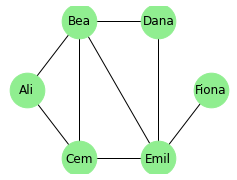

In [ ]:
import matplotlib.pyplot as plt
import networkx as nx

G = nx.Graph([('Ali', 'Bea'), ('Ali', 'Cem'), ('Bea', 'Cem'), ('Bea', 'Dana'), ('Cem', 'Emil'), ('Dana', 'Emil'),
              ('Emil', 'Fiona'), ('Bea', 'Emil')])
pos = {'Ali': (0, 1), 'Bea': (1, 2), 'Cem': (1, 0), 'Dana': (2.5, 2), 'Emil': (2.5, 0), 'Fiona': (3.5, 1)}
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
import networkx as nx

G = nx.Graph([('Ali', 'Bea'), ('Ali', 'Cem'), ('Bea', 'Cem'), ('Bea', 'Dana'), ('Cem', 'Emil'), ('Dana', 'Emil'),
              ('Emil', 'Fiona'), ('Bea', 'Emil')])
pos = {'Ali': (0, 1), 'Bea': (1, 2), 'Cem': (1, 0), 'Dana': (2.5, 2), 'Emil': (2.5, 0), 'Fiona': (3.5, 1)}
fig, ax = plt.subplots(figsize=(4, 3))
nx.draw(G, pos, ax=ax, with_labels=True, node_color='lightgreen', node_size=1200)
plt.show()
```

</details>

#### Aufgabe 6.2

Zeichne das Straßennetz mit den Koordinaten aus `pos`, Beschriftung (Schriftgröße 8: `font_size=8`), Knotenfarbe `'orange'`, Knotengröße 300 und die Entfernungen an den Kanten.
Bildgröße 5 × 4.

**Erwartete Ausgabe:**

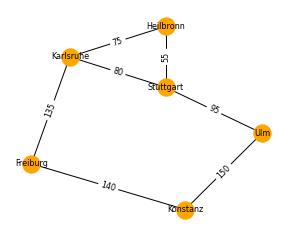

In [ ]:
import matplotlib.pyplot as plt
import networkx as nx

S = nx.Graph()
S.add_weighted_edges_from([('Stuttgart', 'Karlsruhe', 80), ('Stuttgart', 'Ulm', 95), ('Stuttgart', 'Heilbronn', 55),
                          ('Karlsruhe', 'Heilbronn', 75), ('Karlsruhe', 'Freiburg', 135), ('Ulm', 'Konstanz', 150), ('Freiburg', 'Konstanz', 140)])
pos = {'Stuttgart': (4, 4), 'Karlsruhe': (1.5, 5), 'Ulm': (6.5, 2.5), 'Heilbronn': (4, 6), 'Freiburg': (0.5, 1.5), 'Konstanz': (4.5, 0)}
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
import networkx as nx

S = nx.Graph()
S.add_weighted_edges_from([('Stuttgart', 'Karlsruhe', 80), ('Stuttgart', 'Ulm', 95), ('Stuttgart', 'Heilbronn', 55),
                          ('Karlsruhe', 'Heilbronn', 75), ('Karlsruhe', 'Freiburg', 135), ('Ulm', 'Konstanz', 150), ('Freiburg', 'Konstanz', 140)])
pos = {'Stuttgart': (4, 4), 'Karlsruhe': (1.5, 5), 'Ulm': (6.5, 2.5), 'Heilbronn': (4, 6), 'Freiburg': (0.5, 1.5), 'Konstanz': (4.5, 0)}
fig, ax = plt.subplots(figsize=(5, 4))
nx.draw(S, pos, ax=ax, with_labels=True, font_size=8, node_color='orange', node_size=300)
nx.draw_networkx_edge_labels(S, pos, edge_labels=nx.get_edge_attributes(S, 'weight'), ax=ax, font_size=8)
plt.show()
```

</details>

#### Aufgabe 6.3

Zeichne den Web-Graphen `W` als gerichteten Graphen mit Pfeilen, Beschriftung, Knotenfarbe `'lightblue'`, Knotengröße 1500, Schriftgröße 8 und den Koordinaten aus `pos`.
Färbe dabei die Knoten nach Eingangsgrad: `node_color` darf auch eine Liste von Farben in der Reihenfolge von `W.nodes` sein; Seiten mit Eingangsgrad 2 oder mehr `'salmon'`, die anderen `'lightblue'`.
Bildgröße 4 × 3.

**Erwartete Ausgabe:**

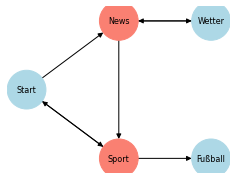

In [ ]:
import matplotlib.pyplot as plt
import networkx as nx

W = nx.DiGraph([('Start', 'News'), ('Start', 'Sport'), ('News', 'Sport'), ('Sport', 'Start'), ('News', 'Wetter'), ('Wetter', 'News'), ('Sport', 'Fußball')])
pos = {'Start': (0, 1), 'News': (2, 2), 'Sport': (2, 0), 'Wetter': (4, 2), 'Fußball': (4, 0)}
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
import networkx as nx

W = nx.DiGraph([('Start', 'News'), ('Start', 'Sport'), ('News', 'Sport'), ('Sport', 'Start'), ('News', 'Wetter'), ('Wetter', 'News'), ('Sport', 'Fußball')])
pos = {'Start': (0, 1), 'News': (2, 2), 'Sport': (2, 0), 'Wetter': (4, 2), 'Fußball': (4, 0)}
farben = []
for v in W.nodes:
    if W.in_degree(v) >= 2:
        farben.append('salmon')
    else:
        farben.append('lightblue')
fig, ax = plt.subplots(figsize=(4, 3))
nx.draw(W, pos, ax=ax, with_labels=True, node_color=farben, node_size=1500, font_size=8, arrows=True)
plt.show()
```

</details>

## 7. Gemischte Übungen

#### Aufgabe 7.1

Das Liniennetz einer kleinen Stadt: Jede Linie ist eine Liste von Haltestellen; aufeinanderfolgende Haltestellen sind verbunden. Baue den Graphen und gib die Anzahl der Haltestellen,
die Anzahl der Verbindungen und die **Umsteigehaltestellen** aus (Grad mindestens 3), sortiert.

**Erwartete Ausgabe:**
```
8 8
['Markt', 'Schule']
```

In [ ]:
import networkx as nx

linien = {'1': ['Bahnhof', 'Markt', 'Rathaus', 'Uni'], '2': ['Klinik', 'Markt', 'Schule', 'Stadion'], '3': ['Bahnhof', 'Schule', 'See']}
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

linien = {'1': ['Bahnhof', 'Markt', 'Rathaus', 'Uni'], '2': ['Klinik', 'Markt', 'Schule', 'Stadion'], '3': ['Bahnhof', 'Schule', 'See']}
G = nx.Graph()
for halte in linien.values():
    for i in range(len(halte) - 1):
        G.add_edge(halte[i], halte[i + 1])
print(G.number_of_nodes(), G.number_of_edges())
umsteigen = []
for v in G.nodes:
    if G.degree(v) >= 3:
        umsteigen.append(v)
print(sorted(umsteigen))
```

</details>

#### Aufgabe 7.2

Ein Wörter-Graph: Zwei Wörter aus `woerter` sind verbunden, wenn sie sich in **genau einem** Buchstaben an derselben Stelle unterscheiden (z. B. `Hand` und `Hund`). Baue den Graphen
mit zwei Schleifen über alle Paare und gib die Nachbarn von `Hand` und den Grad von `Wand` aus.

**Erwartete Ausgabe:**
```
['Hund', 'Wand', 'Rand', 'Band']
4
```

In [ ]:
import networkx as nx

woerter = ['Hand', 'Hund', 'Wand', 'Rand', 'Rind', 'Wind', 'Bund', 'Band', 'Wild']
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

woerter = ['Hand', 'Hund', 'Wand', 'Rand', 'Rind', 'Wind', 'Bund', 'Band', 'Wild']
def unterschiede(a, b):
    n = 0
    for x, y in zip(a, b):
        if x != y:
            n += 1
    return n

G = nx.Graph()
G.add_nodes_from(woerter)
for i in range(len(woerter)):
    for j in range(i + 1, len(woerter)):
        if unterschiede(woerter[i], woerter[j]) == 1:
            G.add_edge(woerter[i], woerter[j])
print(list(G.neighbors('Hand')))
print(G.degree('Wand'))
```

</details>

#### Aufgabe 7.3

Ein Turnier „jeder gegen jeden“: Die Ergebnisse stehen in `spiele` als (Sieger, Verlierer). Speichere sie als gerichteten Graphen (Kante vom Sieger zum Verlierer). Gib die Tabelle aus:
für jedes Team die Siege (Ausgangsgrad) und Niederlagen (Eingangsgrad), sortiert nach Siegen.

**Erwartete Ausgabe:**
```
Rot 2 1
Grün 2 1
Blau 1 2
Gelb 1 2
```

In [ ]:
import networkx as nx

spiele = [('Rot', 'Blau'), ('Grün', 'Rot'), ('Rot', 'Gelb'), ('Blau', 'Grün'), ('Gelb', 'Blau'), ('Grün', 'Gelb')]
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

spiele = [('Rot', 'Blau'), ('Grün', 'Rot'), ('Rot', 'Gelb'), ('Blau', 'Grün'), ('Gelb', 'Blau'), ('Grün', 'Gelb')]
T = nx.DiGraph(spiele)
for team in sorted(T.nodes, key=lambda v: T.out_degree(v), reverse=True):
    print(team, T.out_degree(team), T.in_degree(team))
```

</details>

#### Aufgabe 7.4

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
import networkx as nx

G = nx.Graph([('a', 'b'), ('b', 'c')])
G.add_edge('c', 'd', weight=5)
G.remove_node('b')
print(list(G.nodes), list(G.edges))
print(G.number_of_edges(), G.size(weight='weight'))
```

In [ ]:
import networkx as nx

G = nx.Graph([('a', 'b'), ('b', 'c')])
G.add_edge('c', 'd', weight=5)
G.remove_node('b')
print(list(G.nodes), list(G.edges))
print(G.number_of_edges(), G.size(weight='weight'))